In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
# import torchvision.transforms.functional as TF
import torch.nn.functional as F
import torch.optim as optim

from PIL import Image
from pathlib import Path

import numpy as np
import pandas as pd
import pickle

import matplotlib.pyplot as plt

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), '../../'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)

from app.synthetic_code.SyntheticGen import * 



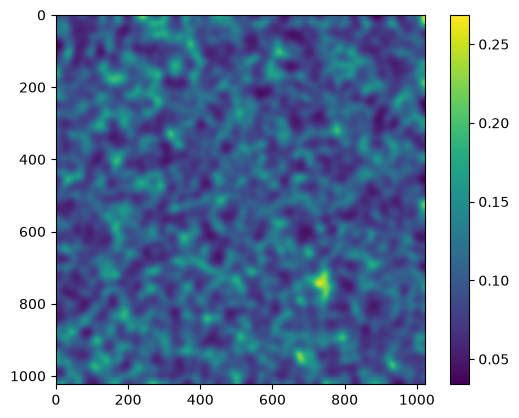

In [14]:
from app.synthetic_code.VectorField import * 

X, Y = vecfield.create_grid(256, 4)
W = np.ones_like(X)
hard_zero_mask = np.zeros(X.shape, dtype=bool)
rng = np.random.default_rng(42)

D = vecfield.make_density(W, hard_zero_mask, .1, 0.5, rng)
plt.imshow(D)
plt.colorbar()

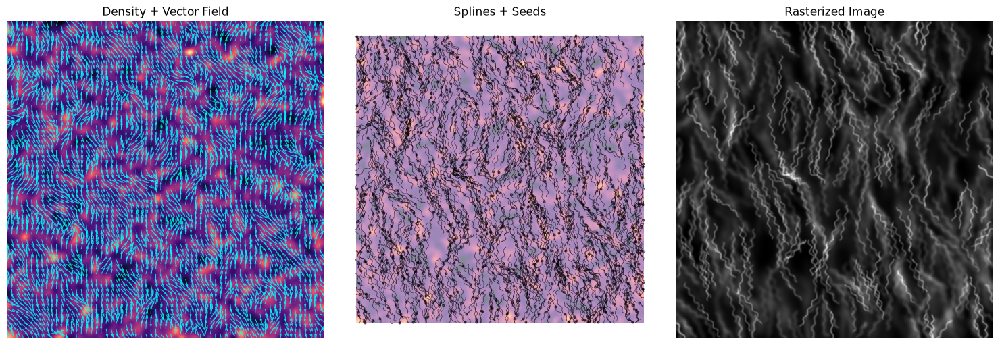

{'Qx': array([[-0.81208394, -0.81293565, -0.81459715, ..., -0.08529902,
         -0.07578641, -0.07100684],
        [-0.81050911, -0.81137301, -0.81305856, ..., -0.09149041,
         -0.08202464, -0.07726835],
        [-0.80741766, -0.80830611, -0.81004011, ..., -0.10385343,
         -0.09448191, -0.08977247],
        ...,
        [-0.97542301, -0.97625093, -0.97785059, ...,  0.65183891,
          0.65984918,  0.66387153],
        [-0.97531144, -0.97614559, -0.97775723, ...,  0.66466935,
          0.67261288,  0.67660077],
        [-0.97525987, -0.97609711, -0.97771467, ...,  0.6710251 ,
          0.67893365,  0.68290349]], shape=(1024, 1024)),
 'Qy': array([[ 0.58354062,  0.58235351,  0.58002712, ...,  0.99635539,
          0.99712406,  0.99747582],
        [ 0.58572601,  0.58452871,  0.5821819 , ...,  0.99580595,
          0.99663029,  0.99701032],
        [ 0.58998026,  0.58876244,  0.58637445, ...,  0.9945926 ,
          0.99552657,  0.99596229],
        ...,
        [ 0.2203405 , 

In [70]:
generate_synthetic_shg_3d(
    seed=10, 
    G_align=0.3, G_density=0.7, G_curve=0, G_conn=0.9,
    L_align=0.4, L_density=0.4, L_conn=1, L_curve=0.6,
    spline_length=60, spline_num=400,
    wave_amplitude_px=6,
    wave_wavelength_px=30,
    L_wave_freq=0.5,
    show_plots=True,
    minimal=True,
    depth=3,
    n_layers=10,
)

In [6]:

def generate_perlin_noise_2d(shape, res, seed=24):
    """
    Generates a 2D array of Perlin Noise.
    
    Parameters:
        shape (tuple): The size of the output grid (height, width).
                       Must be a clean multiple of `res`.
        res (tuple): The number of periods/cells along the (y, x) axes.
        
    Returns:
        np.ndarray: A 2D array containing the noise values scaled between -1 and 1.
    """
    # Ensure grid dimensions align cleanly
    assert shape[0] % res[0] == 0, "Shape height must be a multiple of res height."
    assert shape[1] % res[1] == 0, "Shape width must be a multiple of res width."
    
    # Calculate cell sizes
    delta = (res[0] / shape[0], res[1] / shape[1])
    d = (shape[0] // res[0], shape[1] // res[1])
    
    # 1. Generate the grid coordinates inside each cell [0, 1)
    grid = np.mgrid[0:res[0]:delta[0], 0:res[1]:delta[1]].transpose(1, 2, 0) % 1
    
    # 2. Generate random gradient angles at every vertex
    np.random.seed(seed)
    angles = 2 * np.pi * np.random.rand(res[0] + 1, res[1] + 1)
    gradients = np.dstack((np.cos(angles), np.sin(angles)))
    
    # Helper to tile and scale the vertex gradients across the grid pixels
    def tile_grads(slice_y, slice_x):
        return gradients[slice_y, slice_x].repeat(d[0], 0).repeat(d[1], 1)[:shape[0], :shape[1]]
    
    # 3. Compute dot products between vertex gradients and distance vectors
    dot = lambda grad, ox, oy: grad[..., 0] * ox + grad[..., 1] * oy
    
    n00 = dot(tile_grads(slice(0, -1), slice(0, -1)), grid[..., 0],     grid[..., 1])
    n10 = dot(tile_grads(slice(1, None), slice(0, -1)), grid[..., 0] - 1, grid[..., 1])
    n01 = dot(tile_grads(slice(0, -1), slice(1, None)), grid[..., 0],     grid[..., 1] - 1)
    n11 = dot(tile_grads(slice(1, None), slice(1, None)), grid[..., 0] - 1, grid[..., 1] - 1)
    
    # 4. Apply Perlin's quintic fade function for smooth transitions
    fade = lambda t: 6 * t**5 - 15 * t**4 + 10 * t**3
    t = fade(grid)
    
    # 5. Interpolate the dot products across both dimensions
    # Linear interpolation wrapper
    lerp = lambda a, b, x: a + x * (b - a)
    
    return lerp(lerp(n00, n10, t[..., 0]), lerp(n01, n11, t[..., 0]), t[..., 1])


def fractal_perlin_noise_2d(shape, res, octaves=4, persistence=0.5, lacunarity=2.0, seed=24):
    noise = np.zeros(shape)
    frequency = res
    amplitude = 1.0
    for _ in range(octaves):
        noise += amplitude * generate_perlin_noise_2d(shape, frequency, seed=seed)
        frequency = (int(frequency[0] * lacunarity), int(frequency[1] * lacunarity))
        amplitude *= persistence
    
    # normalize
    noise_min = noise.min()
    noise_max = noise.max()
    if noise_max > noise_min:
        noise = (noise - noise_min) / (noise_max - noise_min)
    return noise

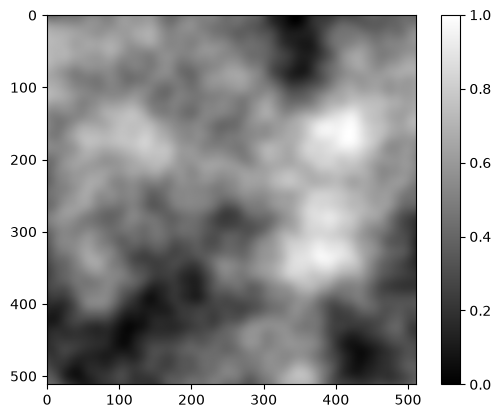

In [7]:
image_shape = (512, 512)
frequency = (2, 2) 



noise_array = fractal_perlin_noise_2d(image_shape, frequency, octaves=4, seed=24)
# fig, axes = plt.subplots(2, 2, figsize=(10, 10))
# seeds = [24, 42, 100, 7]
# for ax, seed in zip(axes.flatten(), seeds):
#     noise_array = fractal_perlin_noise_2d(image_shape, frequency, octaves=8, seed=seed)
#     ax.imshow(noise_array, cmap='gray')
#     ax.set_title(f"Seed: {seed}")
#     ax.axis('off')

# plt.tight_layout()
# plt.show()
plt.imshow(noise_array, cmap='gray')
plt.colorbar()

# plot grid of noise textures with different seeds


(1024, 1024)


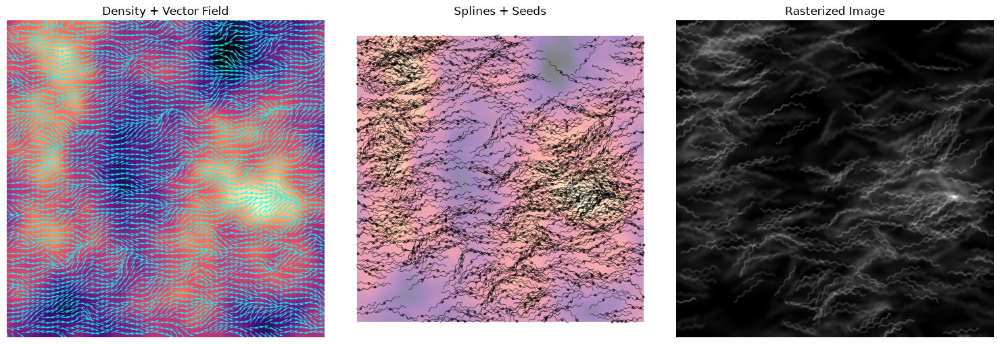

In [20]:
resolution_factor = 4

image_shape = (256*resolution_factor, 256*resolution_factor)
frequency = (2, 2) 

noise_array = fractal_perlin_noise_2d(image_shape, frequency, octaves=4, seed=43)
print(noise_array.shape)
res = generate_synthetic_shg_3d(
    seed=10, 
    G_align=0.3, G_density=0.7, G_curve=0, G_conn=0.9,
    L_align=0.4, L_density=0.4, L_conn=1, L_curve=0.6,
    spline_length=60, spline_num=400,
    wave_amplitude_px=6,
    wave_wavelength_px=30,
    L_wave_freq=0.5,
    show_plots=True,
    minimal=True,
    depth=3,
    n_layers=10,
    custom_density=noise_array,
)

In [ ]:
import random

n=0

seed = random.randint(0, 1000000)

G_align = round(random.uniform(0.005, 1.0), 2)
G_density = round(random.uniform(0.005, 1.0), 2)
G_curve = round(random.uniform(0, 1.0), 2)
G_conn = round(random.uniform(0, 1.0), 2)

L_align = round(random.uniform(0.005, 1.0), 2)
L_density = round(random.uniform(0.005, 1.0), 2)
L_curve = round(random.uniform(0, 1.0), 2)
L_conn = round(random.uniform(0, 1.0), 2)

spline_length = int(round(random.uniform(10, 400), 1))
spline_num = int(round(random.uniform(500, 3000), 1))

wave_amplitude_px = int(round(random.uniform(0, 10)))
wave_wavelength_px = int(round(random.uniform(10, 70)))

L_wave_freq = round(random.uniform(0, 1.0), 2)


depth = random.uniform(0.0, 10.0)

focal_depth_percentage = random.uniform(0.0, 1)

resolution_factor = 2

image_shape = (256*resolution_factor, 256*resolution_factor)
frequency = (2, 2) 

density = fractal_perlin_noise_2d(image_shape, frequency, octaves=4, seed=seed)

# meta_data = [
#     G_align, G_density, G_curve, G_conn,
#     L_align, L_density, L_curve, L_conn, 
#     spline_length, spline_num, 
#     wave_amplitude_px, wave_wavelength_px, 
#     L_wave_freq, 
#     depth,
#     focal_depth_percentage,
#     density
# ]
parameters = {
    "G_align": G_align,
    "G_density": G_density,
    "G_curve": G_curve,
    "G_conn": G_conn,
    "L_align": L_align,
    "L_density": L_density,
    "L_curve": L_curve,
    "L_conn": L_conn,
    "spline_length": spline_length,
    "spline_num": spline_num,
    "wave_amplitude_px": wave_amplitude_px,
    "wave_wavelength_px": wave_wavelength_px,
    "L_wave_freq": L_wave_freq,
    "depth": depth,
    "density": density
}

# res = generate_synthetic_shg(
#     resolution_factor=resolution_factor,
#     seed=seed, 
#     G_align=G_align, G_density=G_density, G_curve=G_curve, G_conn=G_conn,
#     L_align=L_align, L_density=L_density, L_conn=L_conn, L_curve=L_curve,
#     spline_length=spline_length, spline_num=spline_num,
#     wave_amplitude_px=wave_amplitude_px,      # bump for visibly wavier fibers
#     wave_wavelength_px=wave_wavelength_px,    # None -> auto from fiber_width_px
#     L_wave_freq=L_wave_freq,
#     show_plots=False,
#     minimal=True,
# )

print(parameters)

res = generate_synthetic_shg_3d(
    seed=seed, 
    G_align=G_align, G_density=G_density, G_curve=G_curve, G_conn=G_conn,
    L_align=L_align, L_density=L_density, L_conn=L_conn, L_curve=L_curve,
    spline_length=spline_length, spline_num=int(spline_num/10), # divided by n layers
    wave_amplitude_px=wave_amplitude_px,      # bump for visibly wavier fibers
    wave_wavelength_px=wave_wavelength_px,    # None -> auto from fiber_width_px
    L_wave_freq=L_wave_freq,
    show_plots=False,
    minimal=True,
    depth=depth,
    n_layers=10,
    focal_depth=focal_depth_percentage*depth, #this parameters doesent actuall matter because sampling is uniform
    custom_density=density,
)

res['parameters'] = parameters
save = f"{seed}_{n}"

with open(f"{'./test'}/synthetic_{save}.pkl", "wb") as f:
    pickle.dump(res, f)

{'G_align': 0.89, 'G_density': 0.21, 'G_curve': 0.31, 'G_conn': 0.29, 'L_align': 0.84, 'L_density': 0.61, 'L_curve': 0.64, 'L_conn': 0.89, 'spline_length': 336, 'spline_num': 1507, 'wave_amplitude_px': 4, 'wave_wavelength_px': 38, 'L_wave_freq': 0.34, 'depth': 0.9057323874624079, 'density': array([[0.51578681, 0.50991496, 0.50388157, ..., 0.52101365, 0.51931971,
        0.51756942],
       [0.50624226, 0.50037201, 0.49434702, ..., 0.52064762, 0.51895126,
        0.51720022],
       [0.49684199, 0.49097565, 0.48496166, ..., 0.52020179, 0.51850441,
        0.51675406],
       ...,
       [0.50823798, 0.50991658, 0.51151025, ..., 0.50744998, 0.51193453,
        0.51662546],
       [0.51061579, 0.51229904, 0.51389166, ..., 0.50533411, 0.50982367,
        0.51452071],
       [0.51315662, 0.51484099, 0.5164287 , ..., 0.50347795, 0.50797077,
        0.51267073]], shape=(512, 512))}


ValueError: operands could not be broadcast together with shapes (1024,1024) (512,512) (512,512) 

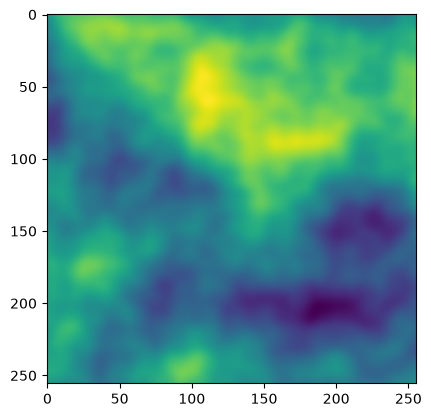

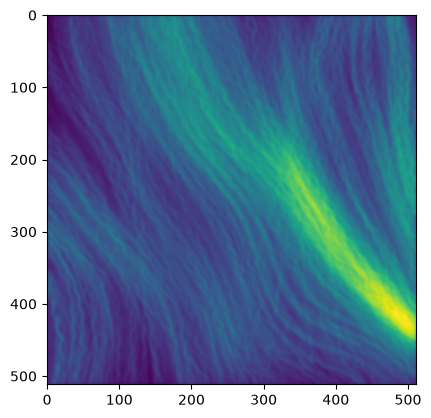

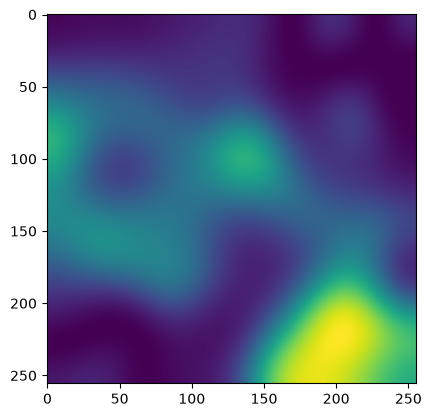

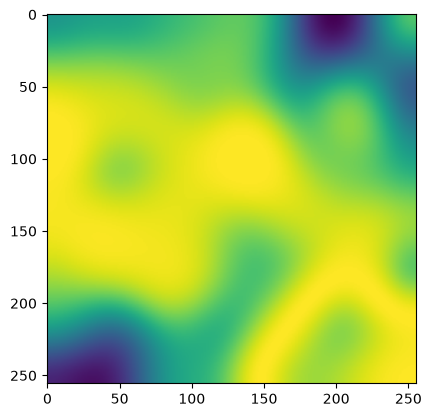

In [51]:
with open('./test/synthetic_622747_1.pkl', 'rb') as file:
    data = pickle.load(file)
    plt.imshow(data['parameters']["density"])
    plt.show()
    plt.imshow(data["image"])
    plt.show()
    plt.imshow(data["Qx"])
    plt.show()
    plt.imshow(data["Qy"])
    plt.show()